# 01 · Business Understanding — NextDeal for BH Assurance
**Agentic AI Project · Option Data Science · FST – Université de Tunis El Manar · 2026/2027**
Supervisor: Dr Olfa Layouni

This notebook covers **Phase 1 (Skill 1 – Understanding a business)**: the business context,
the problem, the SMART business objectives (BOs) with their KPIs, the final data-science
objectives (DSOs) per team member and the objective tree.

> Team members are placeholders (`Member 1 … Member 4`) — edit the `TEAM` list below.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import json
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from src.utils import RAW, set_style, save, PALETTE, INK, INK_2, normalize_label

set_style()
pd.set_option("display.max_colwidth", 120)

TEAM = ["Member 1", "Member 2", "Member 3", "Member 4"]   # <- replace with real names

## 1. Business context

**BH Assurance** is a Tunisian multi-line insurer (life, automobile, fire/property, health,
transport, engineering, liability) belonging to the BH Bank group and listed on the Tunis Stock
Exchange. It sells both to **individuals (personnes physiques – PP)** and **companies
(personnes morales – PM)**, through agents and the bank network (bancassurance).

| Indicator (2025) | BH Assurance | Tunisian market |
|---|---|---|
| Turnover | **208.7 MTND** | **4,255.1 MTND** |
| Growth vs 2024 | **+4.5 %** | **+11.4 %** |
| Net profit | 11.1 MTND (+1 %) | – |
| Fastest-growing line | – | Life: +16.4 %, 31.4 % of the market |
| Largest line | – | Automobile: 38.3 % of the market |

*Sources: L'Economiste Maghrébin (06/04/2026) for BH Assurance; La Presse / AllAfrica
(11/03/2026) citing the insurance supervisory authority for the market.*

**Reading:** BH Assurance grew about **2.5× slower than the market** in 2025, so it is losing
share (≈ 4.9 % of the market, our estimate 208.7 / 4,255.1). The cheapest growth lever for an
insurer is its **existing customer base**: selling a second product to a client already known,
and keeping the contracts it already has.

## 2. Business problem

Quick facts measured on the data we received (details in notebook 02):

In [2]:
pm = pd.read_csv(RAW / "pm_product_portfolio.csv", sep=";", encoding="utf-8-sig")
pp = pd.json_normalize(json.loads((RAW / "pp_contract_renewals.json").read_text()))

products_per_client = pm.groupby("REF_pm")["LIB_PRODUIT"].nunique()
baseline = pd.Series({
    "Corporate clients (PM) in sample": pm["REF_pm"].nunique(),
    "Average products per corporate client": round(products_per_client.mean(), 2),
    "Share of mono-product corporate clients": f"{(products_per_client == 1).mean():.0%}",
    "Distinct products in catalogue sample": pd.concat([pm["LIB_PRODUIT"], pm["candidate_product"]]).nunique(),
    "Expiring individual contracts (PP renewals)": len(pp),
    "Unpaid share among expiring PP contracts": f"{(pp['profile.statut_paiement'] == 'Non payé').mean():.1%}",
}, name="baseline value").to_frame()
baseline

,baseline value
Corporate clients (PM) in sample,299
Average products per corporate client,1.47
Share of mono-product corporate clients,69%
Distinct products in catalogue sample,46
Expiring individual contracts (PP renewals),320
Unpaid share among expiring PP contracts,3.8%


**Problem statement.** BH Assurance's commercial teams face four connected pains:

1. **Under-equipped clients** – 7 in 10 corporate clients hold a single product, although
   their activity (transport, construction, commerce…) exposes them to several insurable risks.
2. **Renewals and unpaid premiums are followed manually** – advisors chase expiry dates and
   invoices by hand, so contacts come late or not at all.
3. **Slow, generic communication** – advisors answer every email themselves, with generic
   pitches that ignore the client's profile and history.
4. **Product knowledge is buried in long general-conditions PDFs**, which makes precise answers
   slow and error-prone.

**Opportunity:** an *agentic* AI sales assistant that (i) knows **which product** each client is
most likely to need, (ii) decides **when and how** to contact them (recommendation, renewal,
payment reminder), (iii) **writes a personalised, compliant message** grounded in the product
documentation, and (iv) keeps a **human advisor in the loop** to validate before sending.

## 3. Starting point – the *NextDeal* prototype

We build on an existing prototype (repo `naderite/Next-BH`). The table below describes the inherited design, not constraints on the new system:

| Component | Technology | Role |
|---|---|---|
| Opportunity data API | FastAPI | serves client profiles + opportunity type (recommend / renew / remind) |
| Agent core | LangChain + **Gemma 3n** (Ollama), Qwen2.5-1.5B fallback | orchestrates the conversation, writes the pitch |
| Intent analysis | zero-shot **XLM-RoBERTa-large-XNLI** + regex rules | detects interest, hesitation, objections |
| RAG | **ChromaDB** + `multilingual-e5-large` | retrieves general-conditions passages |
| Conversations DB | MongoDB | clients, conversations, messages, validation status |
| Admin dashboard | React + Node/Express | human validation of AI drafts, KPIs |
| Channels | Gmail API, Kafka | email in/out, event streaming |

**Gap for this course:** the prototype consumes pre-computed recommendation scores but has no
documented business framing, no reproducible EDA/preparation, and – as notebook 02 shows – its
recommendation score is **leaky**. Our project turns it into a measured, data-driven system. We may redesign its APIs, models and orchestration rather than preserve its interfaces.

## 4. Business objectives (SMART) and KPIs

In [3]:
bos = pd.DataFrame([
    ["BO1", "Grow cross-selling to corporate clients",
     "Raise average products per corporate client from 1.47 to 1.75 and cut the mono-product share from 69 % to 55 % within 12 months.",
     "Products per client · mono-product share · cross-sell conversion rate"],
    ["BO2", "Secure renewals and cash collection",
     "Renew ≥ 90 % of expiring contracts and reduce unpaid premiums at expiry from 3.8 % to < 2 % within 12 months.",
     "Renewal rate · unpaid rate · days between first contact and expiry"],
    ["BO3", "Increase advisor productivity",
     "Automate the drafting of ≥ 70 % of first-level client replies (human-validated) and bring median response time under 2 h during the 6-month pilot.",
     "% automated drafts · approval-without-edit rate · median response time"],
    ["BO4", "Personalised and compliant engagement",
     "Reach a ≥ 25 % reply rate on outreach campaigns with zero non-compliant message sent during the 6-month pilot.",
     "Reply rate · conversion rate · compliance incidents · CSAT"],
], columns=["ID", "Business objective", "SMART formulation", "KPIs"])
bos

,ID,Business objective,SMART formulation,KPIs
0,BO1,Grow cross-selling to corporate clients,Raise average products per corporate client from 1.47 to 1.75 and cut the mono-product share from 69 % to 55 % withi...,Products per client · mono-product share · cross-sell conversion rate
1,BO2,Secure renewals and cash collection,Renew ≥ 90 % of expiring contracts and reduce unpaid premiums at expiry from 3.8 % to < 2 % within 12 months.,Renewal rate · unpaid rate · days between first contact and expiry
2,BO3,Increase advisor productivity,Automate the drafting of ≥ 70 % of first-level client replies (human-validated) and bring median response time under...,% automated drafts · approval-without-edit rate · median response time
3,BO4,Personalised and compliant engagement,Reach a ≥ 25 % reply rate on outreach campaigns with zero non-compliant message sent during the 6-month pilot.,Reply rate · conversion rate · compliance incidents · CSAT


## 5. Data-science objectives (final version)

Rule from the course: every member owns **≥ 3 distinct DSOs**, and **≥ 1 of them includes an
agentic component** (tool-calling, decision-making or orchestration).

In [4]:
dsos = pd.DataFrame([
    [TEAM[0], "BO1", "DSO1.1", "Next-product propensity model ranking the 46 products for each corporate client", "HitRate@3 ≥ 0.70 overall and ≥ 0.40 on long-tail products (popularity baseline: 0.65 / 0.11), client-grouped CV", "ML · ranking"],
    [TEAM[0], "BO1", "DSO1.2", "Segment corporate clients (sector, category, portfolio) into actionable sales personas", "4–8 segments, silhouette ≥ 0.25, validated with business", "ML · clustering"],
    [TEAM[0], "BO1", "DSO1.3", "Expose the model as a tool `recommend_products(client_id, k)` that the agent calls and justifies with RAG", "≥ 90 % valid tool calls on 50 test scenarios", "Agentic · tool-calling"],
    [TEAM[1], "BO2", "DSO2.1", "Score the non-payment risk of contracts approaching expiry", "Recall ≥ 0.70 on 'unpaid' at PR-AUC ≥ 0.40 (needs full history)", "ML · classification"],
    [TEAM[1], "BO2", "DSO2.2", "Recommend complementary guarantees at renewal (association rules on guarantee baskets)", "Rules with lift ≥ 1.5 covering ≥ 60 % of renewals", "ML · association rules"],
    [TEAM[1], "BO2", "DSO2.3", "Renewal orchestration agent: decides reminder / renewal offer / escalation and calls invoice & renewal APIs", "≥ 95 % of contracts contacted ≥ 30 days before expiry (simulation)", "Agentic · decision-making"],
    [TEAM[2], "BO3", "DSO3.1", "Classify client replies into intents & objections (interest, hesitation, already insured, comparison, quote, refusal)", "Macro-F1 ≥ 0.80 on 300 labelled messages", "NLP · classification"],
    [TEAM[2], "BO3", "DSO3.2", "RAG over general conditions to ground every product statement", "Recall@5 ≥ 0.85 on 50 questions · faithfulness ≥ 0.90", "NLP · retrieval"],
    [TEAM[2], "BO3", "DSO3.3", "Conversation orchestrator routing each message to the right strategy/tool with human-in-the-loop", "≥ 70 % of drafts approved without edit", "Agentic · orchestration"],
    [TEAM[3], "BO4", "DSO4.1", "Customer value & loyalty score to prioritise outreach", "Spearman ≥ 0.5 with products held 12 months later", "ML · scoring"],
    [TEAM[3], "BO4", "DSO4.2", "LLM-as-judge quality check of drafts (tone, compliance, personalisation)", "Cohen's κ ≥ 0.6 vs human reviewers", "LLM evaluation"],
    [TEAM[3], "BO4", "DSO4.3", "Monitoring agent that reads logs, computes KPIs and feeds the admin dashboard with weekly insights", "Daily KPI refresh · weekly report generated automatically", "Agentic · tool-calling + dashboard"],
], columns=["Owner", "BO", "DSO", "Objective", "Success criterion", "Type"])
dsos

,Owner,BO,DSO,Objective,Success criterion,Type
0,Member 1,BO1,DSO1.1,Next-product propensity model ranking the 46 products for each corporate client,"HitRate@3 ≥ 0.70 overall and ≥ 0.40 on long-tail products (popularity baseline: 0.65 / 0.11), client-grouped CV",ML · ranking
1,Member 1,BO1,DSO1.2,"Segment corporate clients (sector, category, portfolio) into actionable sales personas","4–8 segments, silhouette ≥ 0.25, validated with business",ML · clustering
2,Member 1,BO1,DSO1.3,"Expose the model as a tool `recommend_products(client_id, k)` that the agent calls and justifies with RAG",≥ 90 % valid tool calls on 50 test scenarios,Agentic · tool-calling
3,Member 2,BO2,DSO2.1,Score the non-payment risk of contracts approaching expiry,Recall ≥ 0.70 on 'unpaid' at PR-AUC ≥ 0.40 (needs full history),ML · classification
4,Member 2,BO2,DSO2.2,Recommend complementary guarantees at renewal (association rules on guarantee baskets),Rules with lift ≥ 1.5 covering ≥ 60 % of renewals,ML · association rules
5,Member 2,BO2,DSO2.3,Renewal orchestration agent: decides reminder / renewal offer / escalation and calls invoice & renewal APIs,≥ 95 % of contracts contacted ≥ 30 days before expiry (simulation),Agentic · decision-making
6,Member 3,BO3,DSO3.1,"Classify client replies into intents & objections (interest, hesitation, already insured, comparison, quote, refusal)",Macro-F1 ≥ 0.80 on 300 labelled messages,NLP · classification
7,Member 3,BO3,DSO3.2,RAG over general conditions to ground every product statement,Recall@5 ≥ 0.85 on 50 questions · faithfulness ≥ 0.90,NLP · retrieval
8,Member 3,BO3,DSO3.3,Conversation orchestrator routing each message to the right strategy/tool with human-in-the-loop,≥ 70 % of drafts approved without edit,Agentic · orchestration
9,Member 4,BO4,DSO4.1,Customer value & loyalty score to prioritise outreach,Spearman ≥ 0.5 with products held 12 months later,ML · scoring


In [5]:
check = dsos.assign(agentic=dsos["Type"].str.startswith("Agentic")).groupby("Owner").agg(
    n_dsos=("DSO", "count"), n_agentic=("agentic", "sum"))
assert (check["n_dsos"] >= 3).all() and (check["n_agentic"] >= 1).all()
check

,n_dsos,n_agentic
Owner,,
Member 1,3,1
Member 2,3,1
Member 3,3,1
Member 4,3,1


## 6. Objective tree
General objective → specific objectives (BOs) → operational objectives (DSOs).

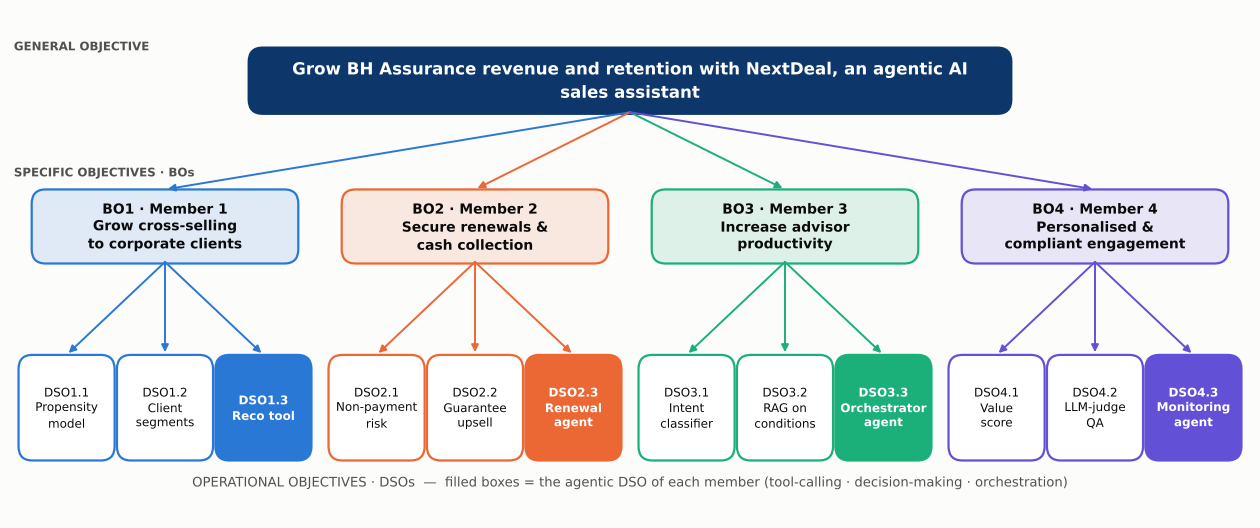

In [6]:
GENERAL = "Grow BH Assurance revenue and retention with NextDeal, an agentic AI sales assistant"
SPECIFIC = {
    "BO1": "Grow cross-selling\nto corporate clients",
    "BO2": "Secure renewals &\ncash collection",
    "BO3": "Increase advisor\nproductivity",
    "BO4": "Personalised &\ncompliant engagement",
}
OPERATIONAL = {
    "BO1": ["Propensity\nmodel", "Client\nsegments", "Reco tool\n(agentic)"],
    "BO2": ["Non-payment\nrisk", "Guarantee\nupsell", "Renewal\nagent"],
    "BO3": ["Intent\nclassifier", "RAG on\nconditions", "Orchestrator\nagent"],
    "BO4": ["Value\nscore", "LLM-judge\nQA", "Monitoring\nagent"],
}
AGENTIC_SLOT = 2   # third DSO of every member is the agentic one

fig, ax = plt.subplots(figsize=(16, 6.6))
ax.set_xlim(0, 16); ax.set_ylim(0.55, 7.0); ax.axis("off")

def box(x, y, w, h, text, face, edge, color=INK, size=10, weight="normal"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.18",
                                fc=face, ec=edge, lw=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=size, color=color, weight=weight, linespacing=1.3)

def link(x1, y1, x2, y2, color):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, shrinkA=0, shrinkB=2))

for y, label in [(6.45, "GENERAL OBJECTIVE"), (4.85, "SPECIFIC OBJECTIVES · BOs")]:
    ax.text(0.05, y, label, fontsize=8.5, color=INK_2, weight="bold", va="bottom")
box(8, 6.1, 9.8, 0.8, "\n".join(textwrap.wrap(GENERAL, 72)), "#0d366b", "#0d366b", "white", 12, "bold")
xs = [2.0, 6.0, 10.0, 14.0]
for i, (bo, label) in enumerate(SPECIFIC.items()):
    c = PALETTE[i] if i != 3 else PALETTE[6]
    link(8, 5.7, xs[i], 4.72, c)
    box(xs[i], 4.25, 3.4, 0.9, f"{bo} · {TEAM[i]}\n{label}", c + "22", c, INK, 10, "bold")
    for j, op in enumerate(OPERATIONAL[bo]):
        ox = xs[i] - 1.27 + j * 1.27
        link(xs[i], 3.8, ox, 2.62, c)
        agentic = j == AGENTIC_SLOT
        text = f"DSO{i+1}.{j+1}\n" + op.replace("\n(agentic)", "").replace(" (agentic)", "")
        box(ox, 1.95, 1.2, 1.3, text, c if agentic else "white", c,
            "white" if agentic else INK, 8.6, "bold" if agentic else "normal")
ax.text(8, 0.95, "OPERATIONAL OBJECTIVES · DSOs  —  filled boxes = the agentic DSO of each member (tool-calling · decision-making · orchestration)",
        ha="center", fontsize=9.5, color=INK_2)
save(fig, "fig00_objective_tree")
plt.show()

## 7. Analytical approach

We follow a **CRISP-DM / TDSP** cycle mapped on the four course phases:

| Phase | Course skill | What we deliver |
|---|---|---|
| 1 · Business understanding | Skill 1 | this notebook – context, BOs, KPIs, DSOs, objective tree |
| 2 · Data acquisition & understanding | Skill 2 | notebooks 02–03 – inventory, EDA, quality, cleaning, encoding |
| 3 · Modeling | Skill 3 | notebook 04 – propensity ranking baseline, then segmentation, risk, NLP, agents |
| 4 · Deployment & feedback | Skill 4 | FastAPI tools + agent + dashboard, monitoring of KPIs |

**Key assumptions / risks**
- The datasets are **extracts** of BH Assurance data shared through the prototype; client identities are pseudonymised.
- Volumes are small (299 companies, 320 expiring individual contracts) → we use client-grouped cross-validation and report uncertainty.
- Some fields are unreliable (constant e-mail, individual age = 0, implausible claim counts) → handled in notebook 03.
- The LLM never sends a message alone: **human validation** stays mandatory (compliance with the rules of the Tunisian insurance regulator, the Haute Autorité de l'Assurance).

## 8. Proposed architecture and improvement over the prototype

**Draft target, not an implemented end-to-end system.** A conversation orchestrator routes each case to a specialised agent or model tool, assembles a draft, and sends it to an advisor for approval, editing or rejection. Client replies re-enter the workflow. LangChain/LangGraph, the LLM, databases and API contracts remain design choices.

| Component | Responsibility | Final DSOs | Current evidence |
|---|---|---|---|
| Cross-sell agent | Call recommendation and segmentation tools; ground proposals in retrieved documentation | DSO1.1, DSO1.2, DSO1.3 | v1 ranking evaluated; v2 recommender and segmentation implemented, not evaluated here; local tool demonstrated |
| Renewal agent | Choose reminder, renewal offer or escalation; call payment-risk and complementary-guarantee tools | DSO2.1, DSO2.2, DSO2.3 | guarantee-rule module implemented, not evaluated here; payment-risk model awaits sufficient history; agent proposed |
| Conversation orchestrator | Route replies using intent classification and retrieval; assemble drafts | DSO3.1, DSO3.2, DSO3.3 | NLP modules implemented, not evaluated here; integrated orchestration proposed |
| Customer-value tool | Prioritise outreach using a value/loyalty score, distinct from segmentation | DSO4.1 | proposed; future-outcome validation required |
| Draft-quality tool | Assess tone, personalisation and compliance before advisor review | DSO4.2 | proposed; human agreement benchmark required |
| Monitoring agent | Read workflow logs, compute BO1–BO4 KPIs and report to the dashboard | DSO4.3 | proposed |

The prototype supplies a starting point. The demonstrated improvement at this milestone is a reproducible, audited tabular pipeline and an evaluated recommendation baseline. Integration and the other evaluations are future work; implementation alone is not proof of performance.
